In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import time
import os
import numpy as np

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
australia_profile = pd.read_parquet("../data/by_country/Australia_macro_profile.parquet")
australia_profile

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
0,2007,NaN,NaN,NaN,NaN,NaN,NaN,78.7775,NaN,283.4875,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2008,NaN,NaN,NaN,NaN,NaN,NaN,87.3575,NaN,309.1825,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009,NaN,NaN,NaN,NaN,NaN,NaN,86.2500,NaN,315.9400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010,NaN,NaN,NaN,NaN,NaN,NaN,89.9575,NaN,341.5600,NaN,NaN,100.0000,NaN,NaN,NaN,NaN,NaN,NaN
4,2011,NaN,NaN,NaN,NaN,NaN,NaN,97.0800,NaN,367.2525,NaN,NaN,97.8450,NaN,NaN,NaN,NaN,NaN,NaN
5,2012,NaN,NaN,NaN,NaN,NaN,NaN,106.9800,101.025,378.9825,NaN,NaN,97.5325,NaN,NaN,NaN,NaN,NaN,NaN
6,2013,NaN,NaN,NaN,NaN,NaN,52.751667,106.8425,103.500,392.4275,NaN,NaN,103.9925,NaN,NaN,NaN,NaN,NaN,NaN
7,2014,NaN,NaN,NaN,NaN,NaN,60.172500,106.6775,106.075,403.4525,2059.295833,NaN,113.4075,NaN,NaN,NaN,NaN,NaN,NaN
8,2015,NaN,102.4,45.31,NaN,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,NaN,123.6450,NaN,NaN,21.87,NaN,5.46,NaN
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53


In [3]:
australia_profile_2015 = australia_profile[(australia_profile['Year'] >= 2015) & (australia_profile['Year'] <= 2024)].copy()
australia_profile_2016 = australia_profile[(australia_profile['Year'] >= 2016) & (australia_profile['Year'] <= 2024)].copy()

In [6]:
australia_profile_2015

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
8,2015,NaN,102.4,45.31,NaN,80.1975,62.596667,105.8950,107.675,409.8350,2207.458333,NaN,123.6450,NaN,NaN,21.87,NaN,5.46,NaN
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350,1.65,23.47,22.09,1.9,5.32,1.50
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050,1.67,24.12,23.18,1.9,5.41,1.56
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400,1.69,25.27,23.38,1.6,5.51,1.54
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525,1.62,25.39,22.56,0.8,5.38,1.57
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925,1.64,25.42,23.03,2.9,5.33,1.47
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200,1.51,27.48,23.60,6.6,5.21,1.53
16,2023,14.50,NaN,NaN,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500,1.52,27.65,NaN,5.6,NaN,1.59
17,2024,NaN,NaN,NaN,NaN,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275,NaN,25.97,NaN,3.2,NaN,NaN


In [4]:
australia_profile_2016

,Year,labor_force,livestock_prod,agr_land,urban_pop,gov_exp,reserves,investment,cpi,gdp,priv_cred,unemployment,house_price,rule_of_law_df,share_of_industry_df,tax_revenue_df,inflation_df,edu_spending_df,govermment_effective_df
9,2016,12.73,96.8,44.54,85.80,85.2900,60.568333,104.4575,109.050,424.6600,2367.798333,5.713333,130.4450,1.72,NaN,22.26,NaN,5.43,1.53
10,2017,13.01,91.0,48.34,85.90,89.7925,73.416667,109.4400,111.175,450.3775,2493.594167,5.606667,141.3350,1.65,23.47,22.09,1.9,5.32,1.50
11,2018,13.31,97.2,46.66,86.01,95.3525,71.986667,114.2550,113.300,473.9000,2550.039167,5.306667,139.3050,1.67,24.12,23.18,1.9,5.41,1.56
12,2019,13.59,97.7,47.12,86.12,103.7050,73.037500,113.9775,115.125,498.6975,2589.645000,5.165000,133.6400,1.69,25.27,23.38,1.6,5.51,1.54
13,2020,13.58,90.6,46.25,86.24,113.1950,65.861667,111.7475,116.100,494.0275,2656.729167,6.441667,140.8525,1.62,25.39,22.56,0.8,5.38,1.57
14,2021,13.80,87.9,47.26,86.36,122.0550,68.871667,127.3975,119.425,550.6875,2760.232500,5.138333,165.3925,1.64,25.42,23.03,2.9,5.33,1.47
15,2022,14.07,87.5,47.26,86.49,133.1300,81.175833,142.0275,127.300,620.9125,2991.540000,3.725833,179.0200,1.51,27.48,23.60,6.6,5.21,1.53
16,2023,14.50,NaN,NaN,86.62,142.2425,90.190000,157.1425,134.425,655.5775,3173.511667,3.686667,178.6500,1.52,27.65,NaN,5.6,NaN,1.59
17,2024,NaN,NaN,NaN,NaN,154.9175,94.169167,166.4175,138.675,680.3275,3340.351667,3.686667,192.5275,NaN,25.97,NaN,3.2,NaN,NaN


In [5]:
australia_profile_2015 = australia_profile_2015.ffill()
australia_profile_2015 = australia_profile_2015.bfill()
australia_profile_2016 = australia_profile_2016.ffill()
australia_profile_2016 = australia_profile_2016.bfill()

In [7]:
def filtrar_columnas(df):
    palabras_clave = [
        'gdp', 'urban_pop', 'gov_exp', 'priv_cred', 'investment',
        'inflation', 'labor_force', 'unemployment', 'edu_spending',
        'rule_of_law', 'govermment_effective'
    ]
    
    columnas_filtradas = [col for col in df.columns if any(palabra in col.lower() for palabra in palabras_clave)]
    return df[columnas_filtradas]

In [8]:
australia_profile_2016 = filtrar_columnas(australia_profile_2016)

In [9]:
australia_profile_2016

,labor_force,urban_pop,gov_exp,investment,gdp,priv_cred,unemployment,rule_of_law_df,inflation_df,edu_spending_df,govermment_effective_df
9,12.73,85.80,85.2900,104.4575,424.6600,2367.798333,5.713333,1.72,1.9,5.43,1.53
10,13.01,85.90,89.7925,109.4400,450.3775,2493.594167,5.606667,1.65,1.9,5.32,1.50
11,13.31,86.01,95.3525,114.2550,473.9000,2550.039167,5.306667,1.67,1.9,5.41,1.56
12,13.59,86.12,103.7050,113.9775,498.6975,2589.645000,5.165000,1.69,1.6,5.51,1.54
13,13.58,86.24,113.1950,111.7475,494.0275,2656.729167,6.441667,1.62,0.8,5.38,1.57
14,13.80,86.36,122.0550,127.3975,550.6875,2760.232500,5.138333,1.64,2.9,5.33,1.47
15,14.07,86.49,133.1300,142.0275,620.9125,2991.540000,3.725833,1.51,6.6,5.21,1.53
16,14.50,86.62,142.2425,157.1425,655.5775,3173.511667,3.686667,1.52,5.6,5.21,1.59
17,14.50,86.62,154.9175,166.4175,680.3275,3340.351667,3.686667,1.52,3.2,5.21,1.59


In [12]:
def plot_and_return_vif(df_country):
    """
    Plots a heatmap of the Variance Inflation Factor (VIF) and returns a DataFrame with VIF values.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns

    Returns:
    - vif_df: DataFrame with variables and their corresponding VIF values
    """
    # Drop 'Year' column and rows with missing values
    df_macro = df_country.drop(columns=['Year'], errors='ignore').dropna()

    # Standardize the data (optional but improves VIF stability)
    df_std = (df_macro - df_macro.mean()) / df_macro.std()

    # Compute VIF values
    vif_data = {
        'Variable': df_std.columns,
        'VIF': [variance_inflation_factor(df_std.values, i) for i in range(df_std.shape[1])]
    }
    vif_df = pd.DataFrame(vif_data).set_index('Variable')

    # Plot heatmap (diagonal matrix for visual emphasis)
    vif_matrix = np.diag(vif_df['VIF'])
    vif_heatmap_df = pd.DataFrame(vif_matrix, index=vif_df.index, columns=vif_df.index)

    plt.figure(figsize=(12, 10))
    sns.heatmap(vif_heatmap_df, annot=True, fmt=".2f", cmap="Reds", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Variance Inflation Factor (VIF) Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return vif_df

In [18]:
def plot_and_return_macro_correlation(df_country):
    """
    Plots a heatmap of the correlation matrix for macroeconomic indicators
    and returns the correlation DataFrame.

    Parameters:
    - df_country: DataFrame with 'Year' and macroeconomic columns

    Returns:
    - corr_matrix: DataFrame with correlation coefficients
    """
    # Drop 'Year' column if present
    df_macro = df_country.drop(columns=['Year'], errors='ignore')

    # Compute correlation matrix
    corr_matrix = df_macro.corr()

    # Plot heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='Reds', square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return corr_matrix


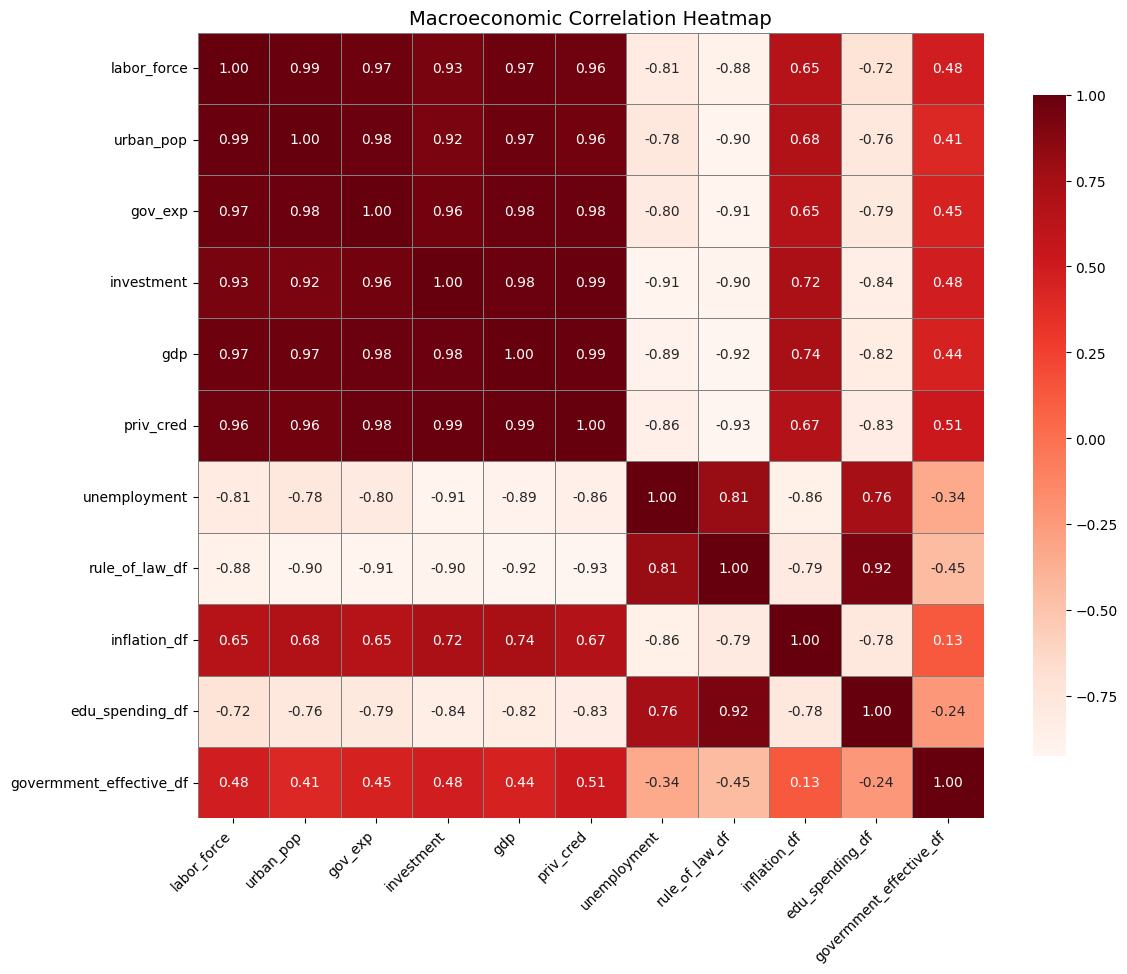

In [19]:
corr_target = plot_and_return_macro_correlation(australia_profile_2016)

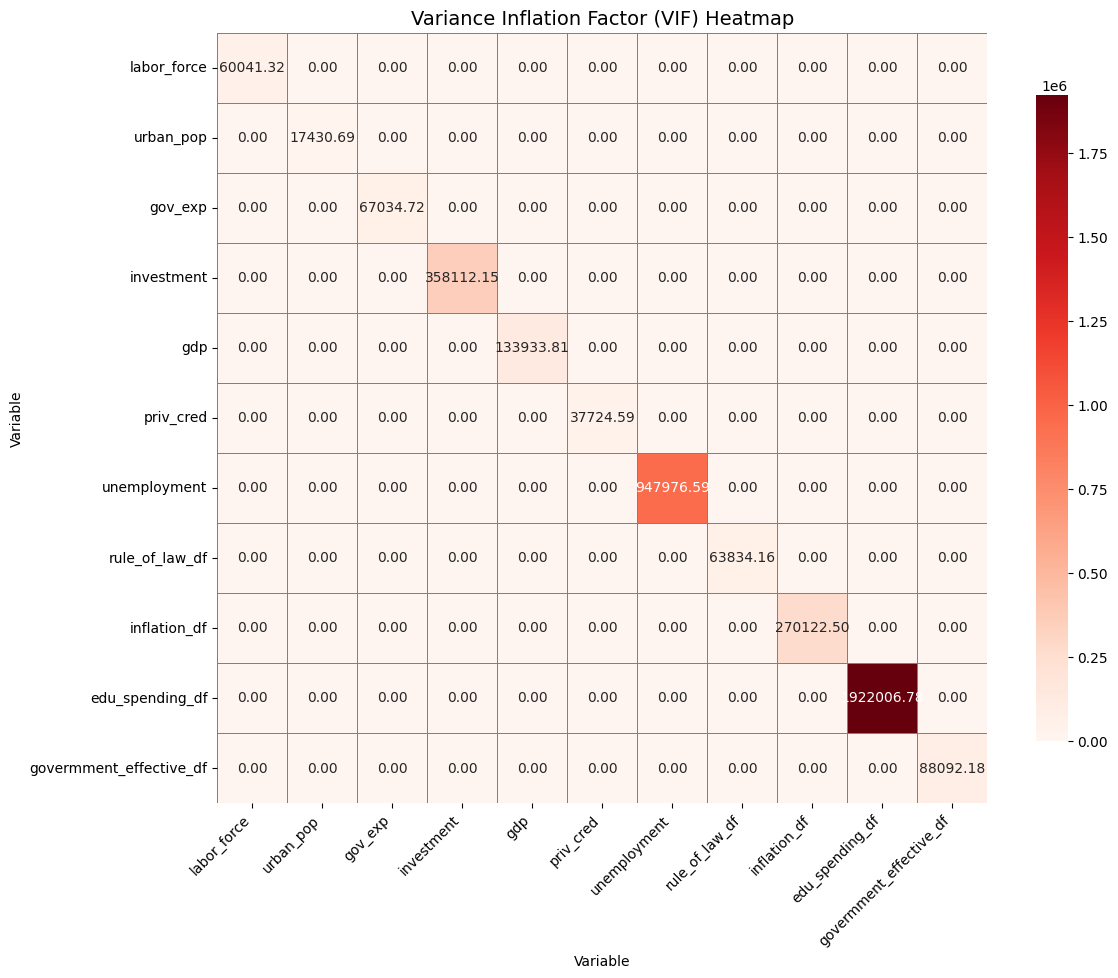

In [17]:
vif_target = plot_and_return_vif(australia_profile_2016)

In [20]:
def imprimir_variables_correlacionadas_con_vif(corr_df, vif_df, umbral_corr=0.8):
    """
    Imprime las variables más correlacionadas por encima del umbral y sus respectivos VIF.

    Parameters:
    - corr_df: DataFrame de correlaciones (output de .corr())
    - vif_df: DataFrame con VIFs (output de la función plot_and_return_vif)
    - umbral_corr: valor mínimo de correlación absoluta para considerar como alta (default: 0.8)
    """
    # Filtrar pares altamente correlacionados (sin duplicados ni diagonal)
    correlaciones_altas = []
    for i in range(len(corr_df.columns)):
        for j in range(i + 1, len(corr_df.columns)):
            var1 = corr_df.columns[i]
            var2 = corr_df.columns[j]
            corr_val = corr_df.iloc[i, j]
            if abs(corr_val) >= umbral_corr:
                correlaciones_altas.append((var1, var2, corr_val))

    # Imprimir resultados
    if correlaciones_altas:
        print(f"\n🔍 Variables con correlación |corr| ≥ {umbral_corr} y sus VIF:")
        for var1, var2, corr_val in correlaciones_altas:
            vif1 = vif_df.loc[var1, 'VIF']
            vif2 = vif_df.loc[var2, 'VIF']
            print(f"- {var1} vs {var2}: correlación = {corr_val:.2f}, VIFs = {vif1:.2f}, {vif2:.2f}")
    else:
        print(f"\n✅ No se encontraron pares con correlación |corr| ≥ {umbral_corr}.")

In [21]:
imprimir_variables_correlacionadas_con_vif(corr_target, vif_target)


🔍 Variables con correlación |corr| ≥ 0.8 y sus VIF:
- labor_force vs urban_pop: correlación = 0.99, VIFs = 60041.32, 17430.69
- labor_force vs gov_exp: correlación = 0.97, VIFs = 60041.32, 67034.72
- labor_force vs investment: correlación = 0.93, VIFs = 60041.32, 358112.15
- labor_force vs gdp: correlación = 0.97, VIFs = 60041.32, 133933.81
- labor_force vs priv_cred: correlación = 0.96, VIFs = 60041.32, 37724.59
- labor_force vs unemployment: correlación = -0.81, VIFs = 60041.32, 947976.59
- labor_force vs rule_of_law_df: correlación = -0.88, VIFs = 60041.32, 63834.16
- urban_pop vs gov_exp: correlación = 0.98, VIFs = 17430.69, 67034.72
- urban_pop vs investment: correlación = 0.92, VIFs = 17430.69, 358112.15
- urban_pop vs gdp: correlación = 0.97, VIFs = 17430.69, 133933.81
- urban_pop vs priv_cred: correlación = 0.96, VIFs = 17430.69, 37724.59
- urban_pop vs rule_of_law_df: correlación = -0.90, VIFs = 17430.69, 63834.16
- gov_exp vs investment: correlación = 0.96, VIFs = 67034.72, 

In [22]:
def resolver_multicolinealidad(df, corr_df, vif_df, umbral_corr=0.8, umbral_vif=10000, max_apariciones=5):
    """
    Elimina iterativamente variables con alta multicolinealidad según correlación y VIF.

    Parameters:
    - df: DataFrame original
    - corr_df: matriz de correlaciones
    - vif_df: tabla de VIFs
    - umbral_corr: umbral de correlación absoluta para considerar redundancia
    - umbral_vif: umbral de VIF para considerar eliminación
    - max_apariciones: número máximo de pares correlados que una variable puede tener antes de considerarse 'dominante'

    Returns:
    - df_reducido: DataFrame con variables redundantes eliminadas
    - variables_eliminadas: lista de nombres de variables eliminadas
    """
    import numpy as np
    df_reducido = df.copy()
    variables_eliminadas = []

    # Contar apariciones en pares correlados
    apariciones = {}
    pares_correlados = []

    for i in range(len(corr_df.columns)):
        for j in range(i + 1, len(corr_df.columns)):
            var1 = corr_df.columns[i]
            var2 = corr_df.columns[j]
            corr_val = corr_df.iloc[i, j]
            if abs(corr_val) >= umbral_corr:
                pares_correlados.append((var1, var2))
                apariciones[var1] = apariciones.get(var1, 0) + 1
                apariciones[var2] = apariciones.get(var2, 0) + 1

    # Iterar sobre pares y eliminar la variable con mayor VIF
    for var1, var2 in pares_correlados:
        if var1 in df_reducido.columns and var2 in df_reducido.columns:
            vif1 = vif_df.loc[var1, 'VIF']
            vif2 = vif_df.loc[var2, 'VIF']

            # Si ambas tienen VIF bajo, conservar
            if vif1 < umbral_vif and vif2 < umbral_vif:
                continue

            # Si una es dominante (aparece mucho), conservarla
            if apariciones.get(var1, 0) > max_apariciones and vif1 < vif2:
                var_a_eliminar = var2
            elif apariciones.get(var2, 0) > max_apariciones and vif2 < vif1:
                var_a_eliminar = var1
            else:
                var_a_eliminar = var1 if vif1 > vif2 else var2

            # Eliminar si no fue ya eliminada
            if var_a_eliminar in df_reducido.columns:
                df_reducido = df_reducido.drop(columns=[var_a_eliminar])
                variables_eliminadas.append(var_a_eliminar)
                print(f"🗑️ Eliminada: {var_a_eliminar} (VIF = {vif_df.loc[var_a_eliminar, 'VIF']:.2f})")

    return df_reducido, variables_eliminadas

In [24]:
df_limpio, eliminadas = resolver_multicolinealidad(australia_profile_2016, corr_target, vif_target)

🗑️ Eliminada: labor_force (VIF = 60041.32)
🗑️ Eliminada: gov_exp (VIF = 67034.72)
🗑️ Eliminada: investment (VIF = 358112.15)
🗑️ Eliminada: gdp (VIF = 133933.81)
🗑️ Eliminada: priv_cred (VIF = 37724.59)
🗑️ Eliminada: rule_of_law_df (VIF = 63834.16)
🗑️ Eliminada: unemployment (VIF = 947976.59)


In [25]:
df_limpio

,urban_pop,inflation_df,edu_spending_df,govermment_effective_df
9,85.80,1.9,5.43,1.53
10,85.90,1.9,5.32,1.50
11,86.01,1.9,5.41,1.56
12,86.12,1.6,5.51,1.54
13,86.24,0.8,5.38,1.57
14,86.36,2.9,5.33,1.47
15,86.49,6.6,5.21,1.53
16,86.62,5.6,5.21,1.59
17,86.62,3.2,5.21,1.59


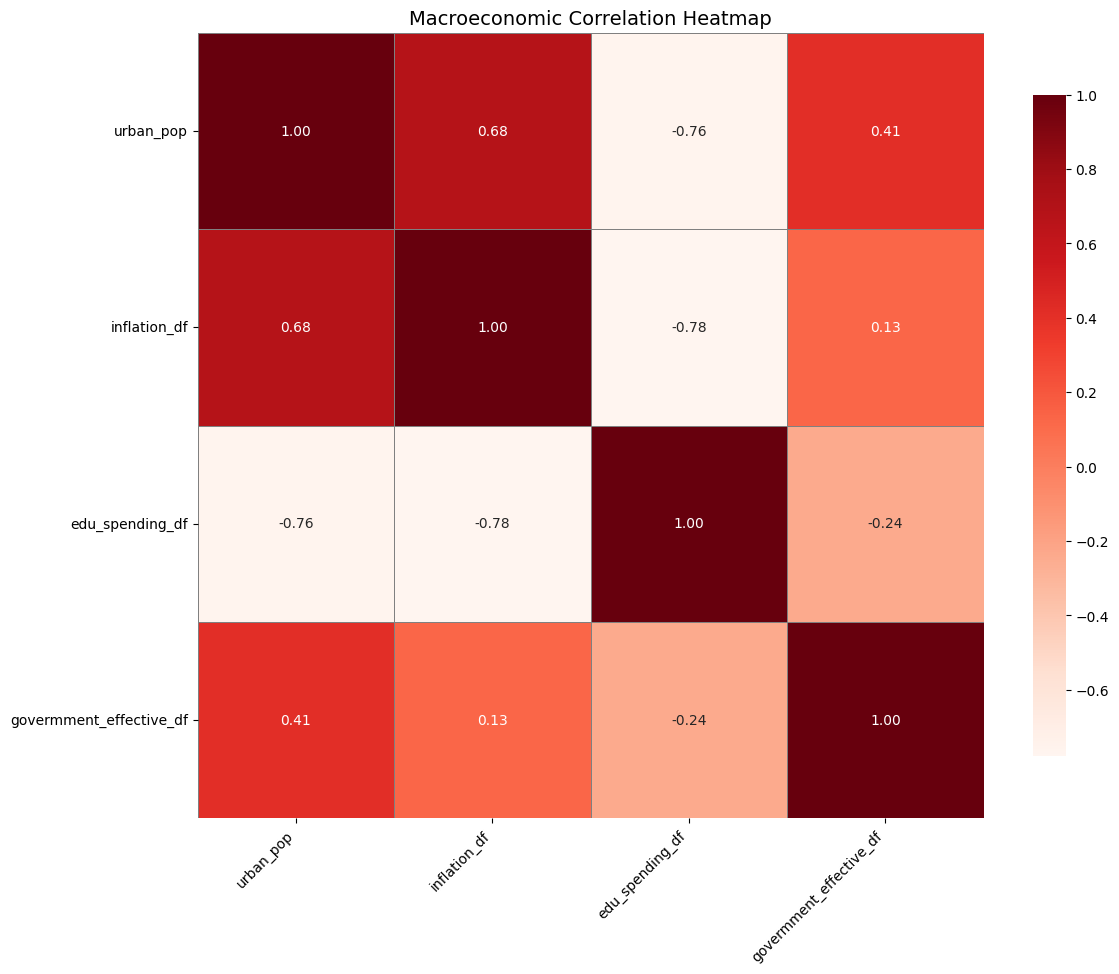

,urban_pop,inflation_df,edu_spending_df,govermment_effective_df
urban_pop,1.000000,0.682906,-0.762296,0.413016
inflation_df,0.682906,1.000000,-0.778848,0.126915
edu_spending_df,-0.762296,-0.778848,1.000000,-0.239850
govermment_effective_df,0.413016,0.126915,-0.239850,1.000000


In [26]:
plot_and_return_macro_correlation(df_limpio)

### Deprecated
- Do not have into account all the possible combinations

In [41]:
def select_correlated_features(corr_matrix, target='house_price', top_n=10, max_intercorrelation=0.7):
    """
    Selects features that are highly correlated with the target variable,
    while minimizing intercorrelation among selected features.

    Parameters:
    - corr_matrix: pandas DataFrame representing the correlation matrix
    - target: name of the target variable (default is 'house_price')
    - top_n: maximum number of top correlated features to consider
    - max_intercorrelation: maximum allowed correlation between selected features

    Returns:
    - List of selected feature names
    """
    # Step 1: Rank features by absolute correlation with the target
    correlations = corr_matrix[target].drop(target).abs().sort_values(ascending=False)
    candidates = correlations.head(top_n).index.tolist()

    selected = []

    for feature in candidates:
        is_valid = True
        for chosen in selected:
            if abs(corr_matrix.loc[feature, chosen]) > max_intercorrelation:
                is_valid = False
                break
        if is_valid:
            selected.append(feature)
    
    features_to_plot = selected + ['house_price'] if 'house_price' not in selected else selected
    corr_subset = corr_matrix.loc[features_to_plot, features_to_plot]

    
    # Plot heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_subset, annot=True, fmt=".2f", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return selected

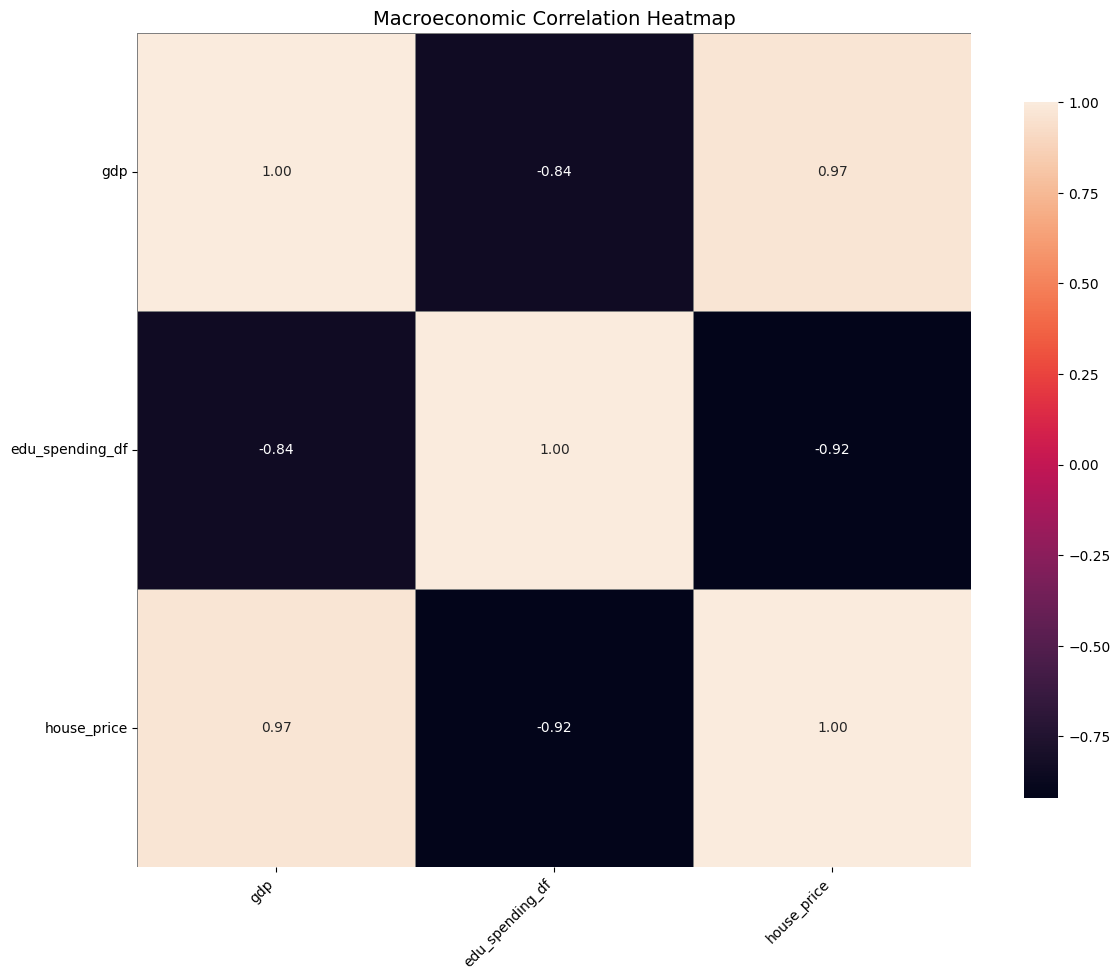

['gdp', 'edu_spending_df']

In [64]:
select_correlated_features(australia_profile_2015.corr(), max_intercorrelation=0.89)

### Deprecated
- Not all possible directions of the relationship are considered.
- If it finds two correlated features with an abs value above the threshold, it ignores them.
- This leaves out valuable information about negative correlations.  

In [38]:
def select_diverse_correlated_features(corr_matrix, target='house_price', min_correlation=0.5, max_intercorrelation=0.7):
    """
    Selects features that are strongly correlated with the target variable,
    while minimizing intercorrelation among selected features.

    Parameters:
    - corr_matrix: pandas DataFrame representing the correlation matrix
    - target: name of the target variable (default is 'house_price')
    - min_correlation: minimum absolute correlation with the target to be considered
    - max_intercorrelation: maximum allowed absolute correlation between selected features

    Returns:
    - List of selected feature names
    """
    # Step 1: Filter features with strong correlation to the target
    correlations = corr_matrix[target].drop(target)
    strong_candidates = correlations[correlations.abs() >= min_correlation].sort_values(ascending=False)

    selected = []

    for feature in strong_candidates.index:
        is_valid = True
        for chosen in selected:
            if abs(corr_matrix.loc[feature, chosen]) > max_intercorrelation:
                is_valid = False
                break
        if is_valid:
            selected.append(feature)

    features_to_plot = selected + ['house_price'] if 'house_price' not in selected else selected
    corr_subset = corr_matrix.loc[features_to_plot, features_to_plot]

    
    # Plot heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_subset, annot=True, fmt=".2f", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return selected

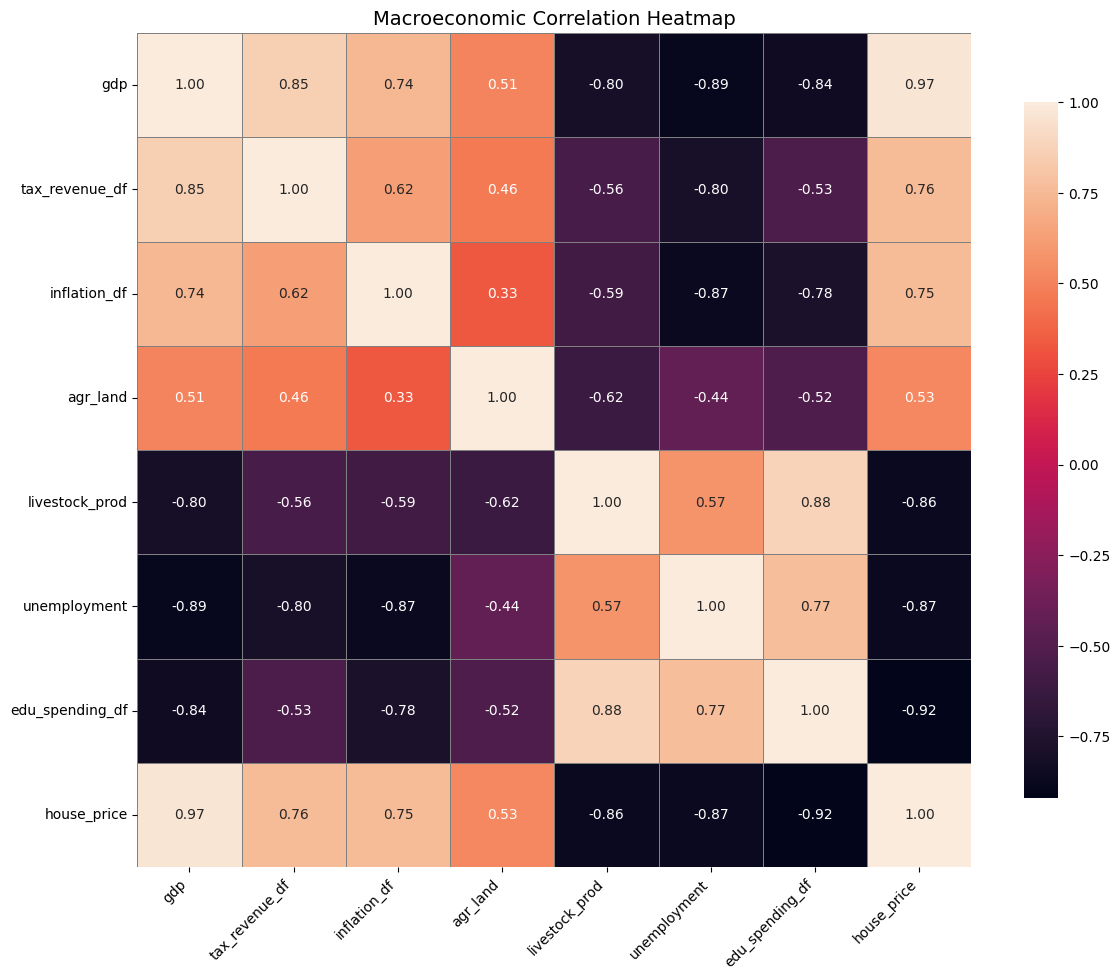

['gdp',
 'tax_revenue_df',
 'inflation_df',
 'agr_land',
 'livestock_prod',
 'unemployment',
 'edu_spending_df']

In [65]:
select_diverse_correlated_features(australia_profile_2015.corr(), max_intercorrelation=0.89)

### Use this
- It considers all possible combinations
- If it finds two features correlated with each other but in opposite directions, it takes this into account to add information

In [53]:
def select_informative_features(corr_matrix, target='house_price', min_correlation=0.5, max_redundancy=0.7):
    """
    Selects features strongly correlated with the target, preserving correlation sign,
    and avoids redundant features even if they move in opposite directions.

    Parameters:
    - corr_matrix: pandas DataFrame of correlations
    - target: name of the target variable (default 'house_price')
    - min_correlation: minimum absolute correlation with the target to be considered
    - max_redundancy: maximum allowed absolute correlation between selected features

    Returns:
    - List of selected feature names
    """
    # Step 1: Filter features with strong correlation to the target (preserving sign)
    correlations = corr_matrix[target].drop(target)
    candidates = correlations[correlations.abs() >= min_correlation].sort_values(ascending=False)

    selected = []

    for feature in candidates.index:
        is_redundant = False
        for chosen in selected:
            # Check absolute correlation between candidate and already selected features
            inter_corr = corr_matrix.loc[feature, chosen]
            if abs(inter_corr) > max_redundancy:
                is_redundant = True
                break
        if not is_redundant:
            selected.append(feature)
    
    features_to_plot = selected + ['house_price'] if 'house_price' not in selected else selected
    corr_subset = corr_matrix.loc[features_to_plot, features_to_plot]

    
    # Plot heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_subset, annot=True, fmt=".2f", square=True,
                cbar_kws={"shrink": 0.8}, linewidths=0.5, linecolor='gray')

    plt.title("Macroeconomic Correlation Heatmap", fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    
    return selected

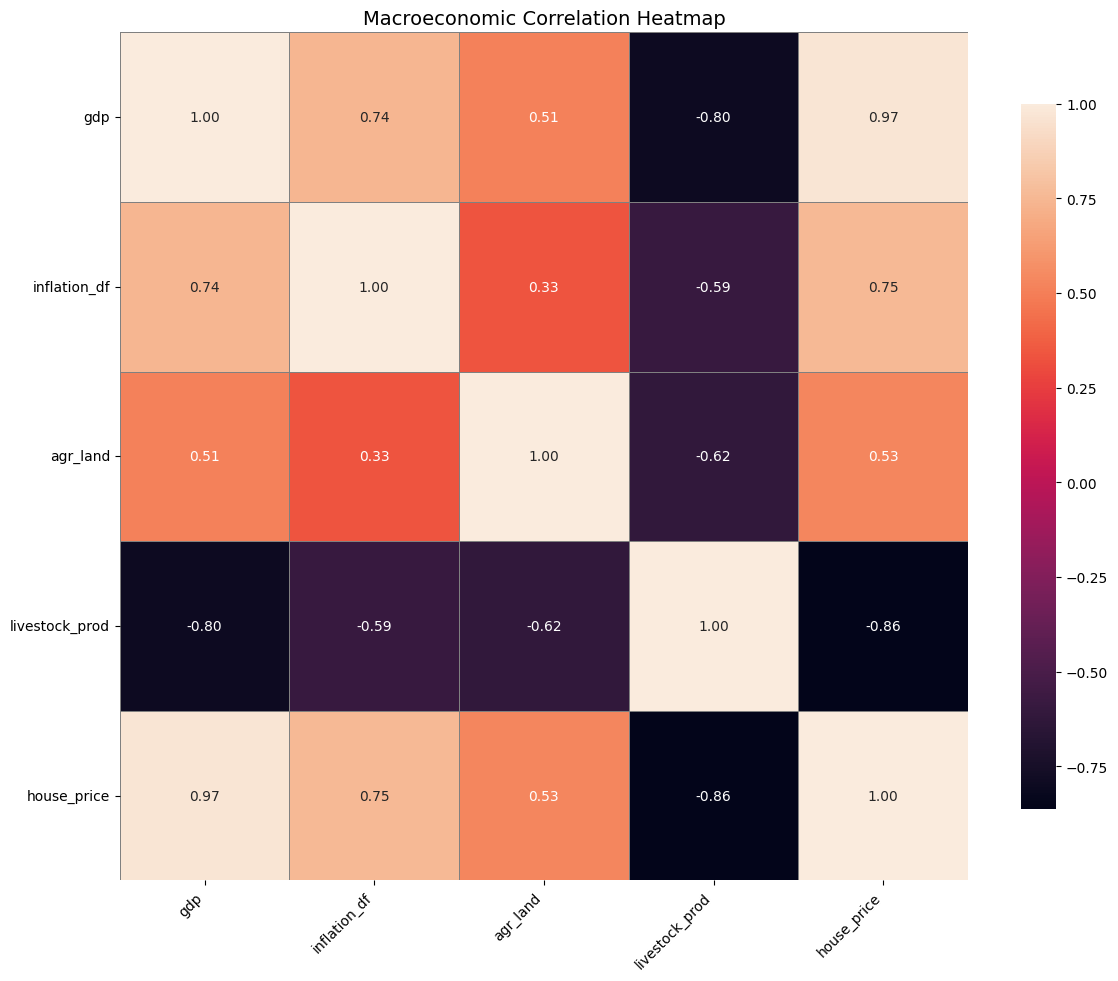

['gdp', 'inflation_df', 'agr_land', 'livestock_prod']

In [67]:
select_informative_features(australia_profile_2015.corr(), max_redundancy=0.85)